In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
# Load your prepared data
df = pd.read_csv('chandigarh_temporal_features.csv')

/tmp/ipykernel_1802/1348992127.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y='AQI', palette='Set2')


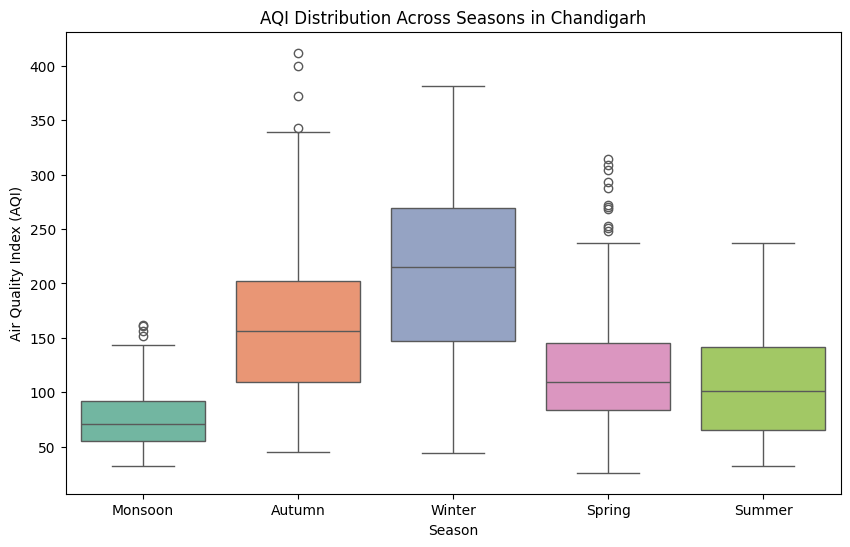

/tmp/ipykernel_1802/1348992127.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Is_Paddy_Harvesting', y='AQI', palette='Reds', errorbar=None)


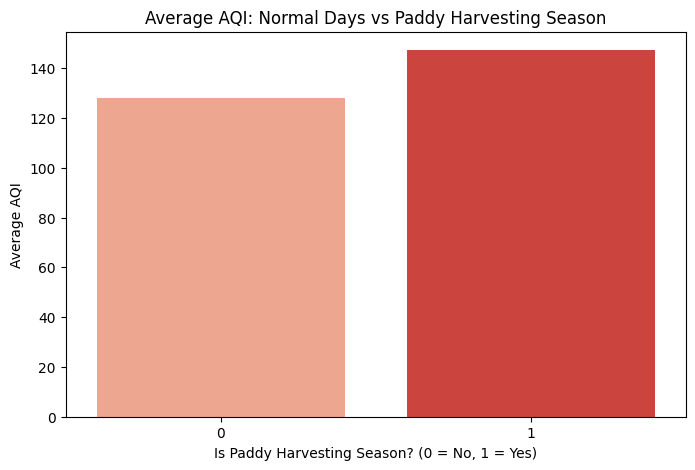

/tmp/ipykernel_1802/1348992127.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Is_Diwali_Season', y='AQI', palette='Oranges', errorbar=None)


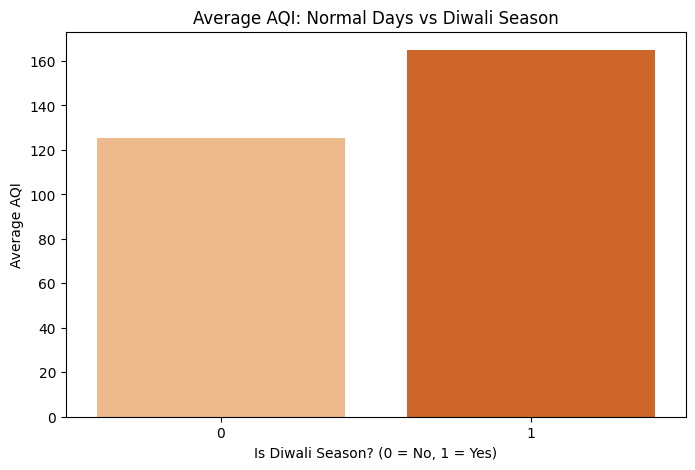

/tmp/ipykernel_1802/1348992127.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=winter_spring_df, x='Month', y='AQI', palette='Blues', errorbar=None)


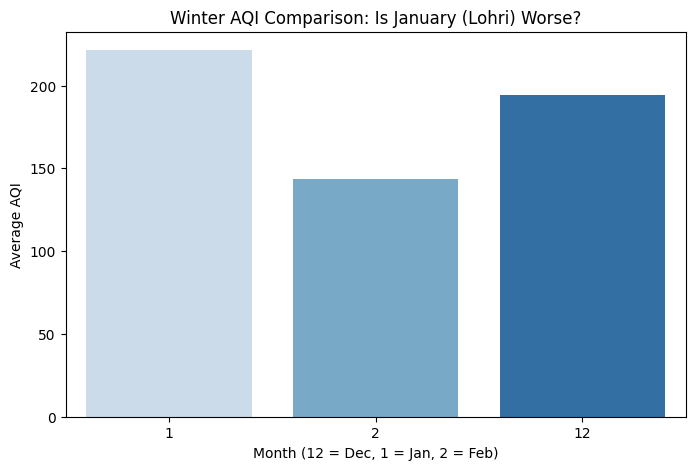

In [10]:
# Chart 1: Seasonal Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Season', y='AQI', palette='Set2')
plt.title('AQI Distribution Across Seasons in Chandigarh')
plt.xlabel('Season')
plt.ylabel('Air Quality Index (AQI)')
plt.show()

# Chart 2: Paddy Harvesting Impact
plt.figure(figsize=(8, 5))
# Calculate the average AQI for harvesting (1) vs non-harvesting (0)
sns.barplot(data=df, x='Is_Paddy_Harvesting', y='AQI', palette='Reds', errorbar=None)
plt.title('Average AQI: Normal Days vs Paddy Harvesting Season')
plt.xlabel('Is Paddy Harvesting Season? (0 = No, 1 = Yes)')
plt.ylabel('Average AQI')
plt.show()

# Chart 3: Diwali Season Impact
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Is_Diwali_Season', y='AQI', palette='Oranges', errorbar=None)
plt.title('Average AQI: Normal Days vs Diwali Season')
plt.xlabel('Is Diwali Season? (0 = No, 1 = Yes)')
plt.ylabel('Average AQI')
plt.show()

# Filter data for just Winter and Spring to isolate the early year
winter_spring_df = df[df['Month'].isin([12, 1, 2])]

# Chart 4: January/Lohri Comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=winter_spring_df, x='Month', y='AQI', palette='Blues', errorbar=None)
plt.title('Winter AQI Comparison: Is January (Lohri) Worse?')
plt.xlabel('Month (12 = Dec, 1 = Jan, 2 = Feb)')
plt.ylabel('Average AQI')
plt.show()

/tmp/ipykernel_1802/1381801836.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Season', y='AQI', palette='Set3')


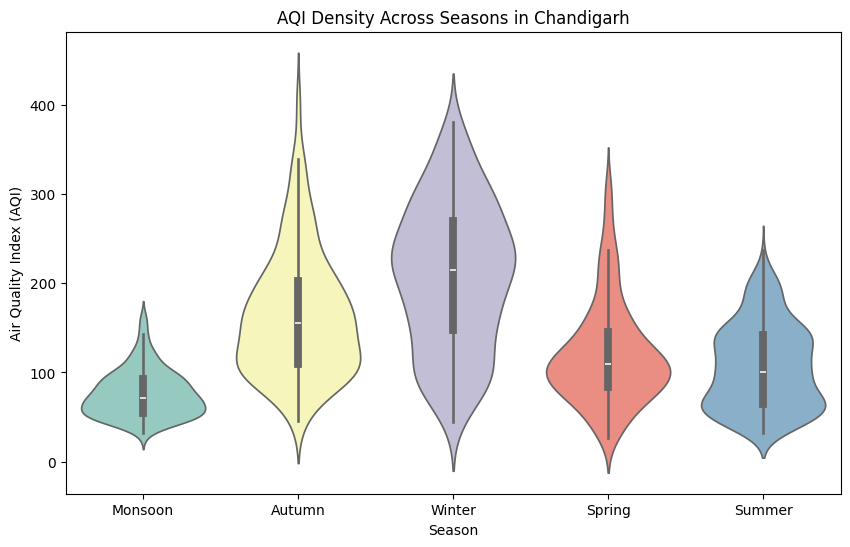

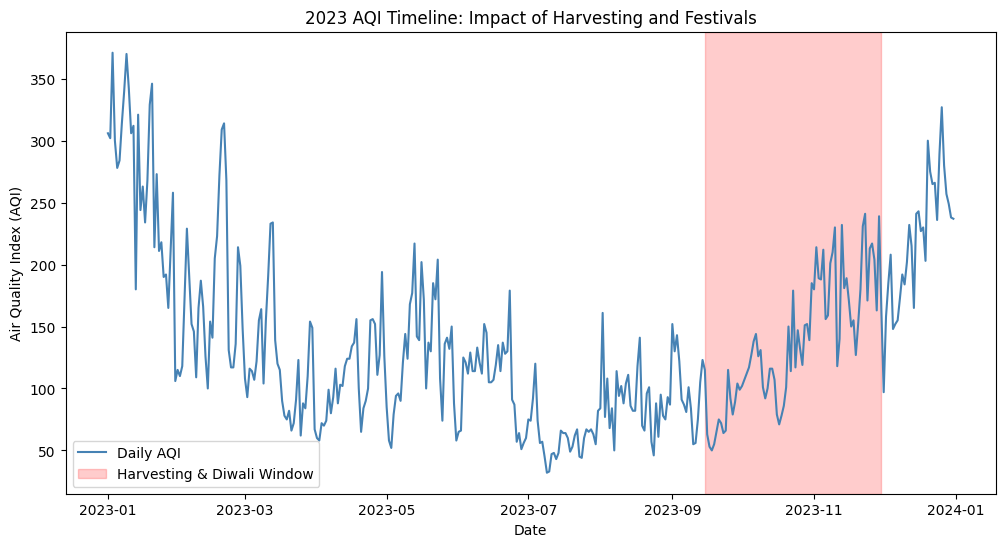

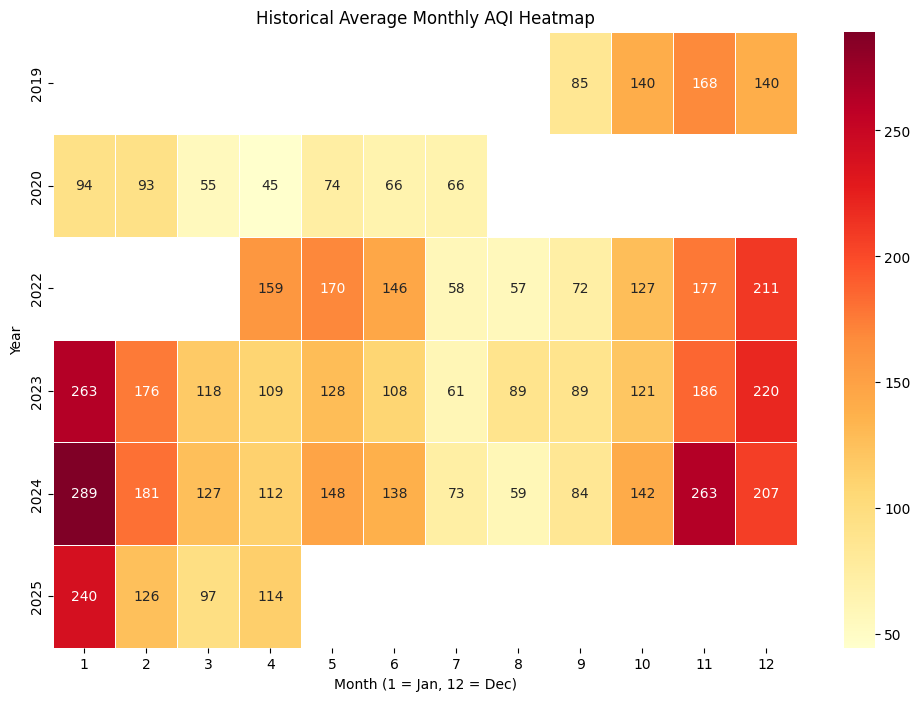

In [13]:
# Assuming 'df' is already loaded from your earlier steps
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

plt.figure(figsize=(10, 6))
# We use violinplot instead of boxplot
sns.violinplot(data=df, x='Season', y='AQI', palette='Set3')

plt.title('AQI Density Across Seasons in Chandigarh')
plt.xlabel('Season')
plt.ylabel('Air Quality Index (AQI)')
plt.show()



# Filter data just for the year 2023 and sort by date
df_2023 = df[df['Year'] == 2023].sort_values('Date')

plt.figure(figsize=(12, 6))
plt.plot(df_2023['Date'], df_2023['AQI'], color='steelblue', label='Daily AQI')

# Define the start and end dates for the shaded region
start_date = pd.to_datetime('2023-09-15')
end_date = pd.to_datetime('2023-11-30')

# axvspan creates the shaded background rectangle
plt.axvspan(start_date, end_date, color='red', alpha=0.2, label='Harvesting & Diwali Window')

plt.title('2023 AQI Timeline: Impact of Harvesting and Festivals')
plt.xlabel('Date')
plt.ylabel('Air Quality Index (AQI)')
plt.legend()
plt.show()



# Create a pivot table calculating the average AQI for each Month/Year combo
heatmap_data = df.pivot_table(index='Year', columns='Month', values='AQI', aggfunc='mean')

plt.figure(figsize=(12, 8))
# cmap='YlOrRd' uses a Yellow-Orange-Red color scale (Red = Worse AQI)
# annot=True puts the actual average AQI numbers inside the boxes
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt=".0f", linewidths=.5)

plt.title('Historical Average Monthly AQI Heatmap')
plt.xlabel('Month (1 = Jan, 12 = Dec)')
plt.ylabel('Year')
plt.show()